# Zela Aí · Priorização de zeladoria com Programação Dinâmica
**Global Solution 2026.2 · CitizenTech · Dynamic Programming**

## 1. Cenário
**CitizenTech:** *Zela Aí*, plataforma em que moradores registram problemas da rua (buraco, lâmpada apagada, entulho, boca de lobo entupida), apoiam os registros dos vizinhos e acompanham o atendimento.

**Cidadão beneficiado:** morador dos bairros da região central de São Paulo (Aclimação, Cambuci, Liberdade e Vila Mariana).

**Problema que este algoritmo resolve:** a equipe de zeladoria tem **8 horas por dia** e o bairro tem dezenas de ocorrências abertas. Hoje o atendimento costuma seguir a **ordem de chegada**, então um buraco perigoso registrado ontem espera atrás de uma poda simples registrada semana passada. A pergunta é:

> **Quais ocorrências a equipe deve atender hoje para resolver o maior impacto possível para os moradores, sem passar da jornada?**

Esse é o **Problema da Mochila 0/1**:

| Mochila | Zela Aí |
|---|---|
| capacidade da mochila | jornada da equipe: 16 blocos de 30 min (8 h) |
| item | ocorrência |
| peso do item | tempo estimado de atendimento (blocos) |
| valor do item | pontuação de impacto |
| 0/1 | a ocorrência é resolvida inteira hoje, ou fica para outro dia |

## 2. Fonte dos dados
- **Base usada:** `dados/ocorrencias_simuladas.csv`, com **40 ocorrências simuladas** pela equipe (script `gerar_dados.py`, semente fixa 42, reprodutível).
- **De onde vem a estrutura:** as categorias reproduzem serviços de zeladoria do **SP156**, o canal de solicitações da Prefeitura de São Paulo. Os registros do SP156 são públicos no Portal de Dados Abertos: <http://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156>.
- **O que é estimativa da equipe:** gravidade (1 a 5), apoios dos vizinhos e tempo de atendimento. Essas colunas não existem na base pública, porque são funcionalidades do Zela Aí.
- **Dados pessoais:** nenhum. Não há nome, CPF ou endereço exato de cidadãos.

**Pontuação de impacto** (inteira e explicável para o cidadão):

$$\text{impacto} = 10 \times \text{gravidade} + 3 \times \min(\text{apoios}, 10) + \min(\text{dias aberta}, 30)$$

O termo de dias em aberto garante que nenhuma ocorrência fique esquecida para sempre: quanto mais tempo espera, mais pontos ganha.

In [1]:
import time, random, inspect, subprocess, sys
import pandas as pd
import matplotlib.pyplot as plt
from priorizacao import *
from simulacao import simular_semana

pd.set_option("display.max_colwidth", 40)
ocorrencias = carregar_csv("dados/ocorrencias_simuladas.csv")
tabela = pd.DataFrame([{**vars(o), "dias_aberta": o.dias_aberta(), "impacto": o.impacto()}
                       for o in ocorrencias])
print(f"{len(ocorrencias)} ocorrências abertas em {DATA_REFERENCIA:%d/%m/%Y}")
print(f"Tempo total pedido: {tabela.tempo_blocos.sum()} blocos ({tabela.tempo_blocos.sum()/2:.0f} h)"
      f" · Jornada disponível: {JORNADA_BLOCOS} blocos ({JORNADA_BLOCOS/2:.0f} h)")
tabela.head(10)

40 ocorrências abertas em 17/11/2026
Tempo total pedido: 147 blocos (74 h) · Jornada disponível: 16 blocos (8 h)


,id,data_registro,categoria,bairro,gravidade,apoios,tempo_blocos,dias_aberta,impacto
0,OC001,2026-10-28,Poda de árvore,Cambuci,4,1,5,20,63
1,OC002,2026-10-28,Limpeza de boca de lobo,Liberdade,5,0,2,20,70
2,OC003,2026-10-29,Limpeza de boca de lobo,Aclimação,3,2,3,19,55
3,OC004,2026-10-30,Iluminação pública (lâmpada apagada),Aclimação,2,2,1,18,44
4,OC005,2026-10-30,Iluminação pública (lâmpada apagada),Aclimação,4,8,2,18,82
5,OC006,2026-10-31,Limpeza de boca de lobo,Vila Mariana,4,0,3,17,57
6,OC007,2026-10-31,Reparo de calçada,Cambuci,2,1,4,17,40
7,OC008,2026-11-02,Poda de árvore,Vila Mariana,4,5,5,15,70
8,OC009,2026-11-02,Limpeza de boca de lobo,Liberdade,5,11,4,15,95
9,OC010,2026-11-03,Tapa-buraco,Cambuci,5,0,4,14,64


In [2]:
tabela.groupby("categoria").agg(qtd=("id", "count"), tempo_medio_blocos=("tempo_blocos", "mean"),
                                impacto_medio=("impacto", "mean")).round(1).sort_values("qtd", ascending=False)

,qtd,tempo_medio_blocos,impacto_medio
categoria,,,
Limpeza de boca de lobo,10,2.9,62.2
Reparo de calçada,10,4.6,43.2
Tapa-buraco,7,3.3,52.1
Poda de árvore,7,4.6,51.7
Iluminação pública (lâmpada apagada),3,1.7,54.3
Remoção de entulho / descarte irregular,3,4.0,46.7


## 3. Modelagem: estruturas de dados escolhidas
| Estrutura | Onde | Por quê |
|---|---|---|
| `dataclass Ocorrencia` | cada registro | agrupa os campos com nome e calcula `impacto()` num só lugar |
| **lista** (array) | ocorrências, pesos e valores | o DP acessa o item *i* por índice em O(1) |
| **matriz** `dp[i][w]` (lista de listas) | tabela da programação dinâmica | guarda cada subproblema uma única vez, sem recalcular |
| **vetor** `dp[w]` | versão otimizada | só precisa da linha anterior, então a memória cai de O(n·W) para O(W) |
| **pilha** (`list` com `append`/`pop`) | reconstrução da resposta | a volta pela tabela encontra as escolhas de trás para frente; desempilhar devolve a ordem original |
| **fila** (`collections.deque`) | estratégia de comparação "ordem de chegada" | `popleft()` em O(1), modelando o atendimento atual (FIFO) |

**Por que programação dinâmica?** O problema tem as duas propriedades necessárias:
1. **Subestrutura ótima:** a melhor escolha com *i* ocorrências e *w* blocos depende da melhor escolha com *i-1* ocorrências.
2. **Subproblemas sobrepostos:** a força bruta testa 2ⁿ combinações e recalcula os mesmos pedaços muitas vezes. O DP resolve cada par (*i*, *w*) **uma vez**.

**Recorrência:**
$$dp[i][w] = \begin{cases} dp[i-1][w] & \text{se } t_i > w \\ \max\big(dp[i-1][w],\; v_i + dp[i-1][w - t_i]\big) & \text{caso contrário} \end{cases}$$

## 4. Algoritmo: código com a ideia central apontada

In [3]:
print(inspect.getsource(mochila_dp))

def mochila_dp(ocorrencias: list[Ocorrencia], capacidade: int,
               hoje: date = DATA_REFERENCIA, devolver_tabela: bool = False):
    """Escolhe o conjunto de ocorrências de maior impacto total que cabe na jornada.

    Retorna (impacto_total, lista_de_ocorrencias_escolhidas[, tabela]).
    Tempo: O(n · W)   Memória: O(n · W)   (n = ocorrências, W = capacidade em blocos)
    """
    n = len(ocorrencias)
    pesos = [o.tempo_blocos for o in ocorrencias]
    valores = [o.impacto(hoje) for o in ocorrencias]

    # IDEIA CENTRAL (1): subproblemas.
    # dp[i][w] = maior impacto possível usando só as i primeiras ocorrências
    #            com no máximo w blocos de tempo.
    dp = [[0] * (capacidade + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        peso, valor = pesos[i - 1], valores[i - 1]
        for w in range(capacidade + 1):
            # IDEIA CENTRAL (2): escolha ótima em cada passo.
            # Opção A: NÃO atender a ocorrência i -> mesmo resultado de i

## 5. Exemplo pequeno de entrada e saída: por que não basta ser guloso
Jornada curta de **4 blocos (2 h)** e três ocorrências:

In [4]:
from datetime import timedelta
def oc(id_, cat, grav, apoios, dias, tempo):
    return Ocorrencia(id_, DATA_REFERENCIA - timedelta(days=dias), cat, "Aclimação", grav, apoios, tempo)

exemplo = [oc("A", "Tapa-buraco", 5, 3, 1, 3),
           oc("B", "Limpeza de boca de lobo", 3, 2, 2, 2),
           oc("C", "Iluminação pública", 3, 2, 2, 2)]
print("ENTRADA (capacidade = 4 blocos)")
for o in exemplo:
    print(f"  {o.id}: {o.categoria:<26} tempo={o.tempo_blocos}  impacto={o.impacto()}  "
          f"impacto/bloco={o.impacto()/o.tempo_blocos:.1f}")

v_g, e_g = guloso_razao(exemplo, 4)
v_dp, e_dp, dp = mochila_dp(exemplo, 4, devolver_tabela=True)
print("\nSAÍDA")
print(f"  Guloso: {[o.id for o in e_g]} -> impacto {v_g}  (A ocupa 3 blocos e sobra 1 inútil)")
print(f"  DP:     {[o.id for o in e_dp]} -> impacto {v_dp}  (+{(v_dp - v_g)/v_g:.0%})")

pd.DataFrame(dp, index=["∅", "+A", "+B", "+C"], columns=[f"w={w}" for w in range(5)])

ENTRADA (capacidade = 4 blocos)
  A: Tapa-buraco                tempo=3  impacto=60  impacto/bloco=20.0
  B: Limpeza de boca de lobo    tempo=2  impacto=38  impacto/bloco=19.0
  C: Iluminação pública         tempo=2  impacto=38  impacto/bloco=19.0

SAÍDA
  Guloso: ['A'] -> impacto 60  (A ocupa 3 blocos e sobra 1 inútil)
  DP:     ['B', 'C'] -> impacto 76  (+27%)


,w=0,w=1,w=2,w=3,w=4
∅,0,0,0,0,0
+A,0,0,0,60,60
+B,0,0,38,60,60
+C,0,0,38,60,76


Na tabela, a linha `+C`, coluna `w=4` contém **76**, o ótimo. A reconstrução volta a partir dela: 76 ≠ 38 (linha de cima), então **C** entra e restam 2 blocos. Na linha `+B`, `w=2`, o valor 38 ≠ 0, então **B** entra. Na linha `+A`, `w=0`, o valor é 0 = 0, então A fica de fora.

## 6. Plano do dia com as 40 ocorrências reais da base

In [5]:
valor, plano = mochila_dp(ocorrencias, JORNADA_BLOCOS)
print(f"Ocorrências escolhidas para hoje: impacto total = {valor}, "
      f"{sum(o.tempo_blocos for o in plano)}/{JORNADA_BLOCOS} blocos usados\n")
pd.DataFrame([{"id": o.id, "categoria": o.categoria, "bairro": o.bairro, "gravidade": o.gravidade,
               "apoios": o.apoios, "dias_aberta": o.dias_aberta(), "tempo_blocos": o.tempo_blocos,
               "impacto": o.impacto()} for o in plano]).sort_values("impacto", ascending=False)

Ocorrências escolhidas para hoje: impacto total = 483, 16/16 blocos usados



,id,categoria,bairro,gravidade,apoios,dias_aberta,tempo_blocos,impacto
3,OC009,Limpeza de boca de lobo,Liberdade,5,11,15,4,95
6,OC033,Limpeza de boca de lobo,Cambuci,5,13,3,3,83
2,OC005,Iluminação pública (lâmpada apagada),Aclimação,4,8,18,2,82
0,OC002,Limpeza de boca de lobo,Liberdade,5,0,20,2,70
5,OC026,Tapa-buraco,Liberdade,3,6,8,2,56
4,OC012,Limpeza de boca de lobo,Aclimação,4,0,13,2,53
1,OC004,Iluminação pública (lâmpada apagada),Aclimação,2,2,18,1,44


## 7. Comparação com o atendimento por ordem de chegada e com o guloso

In [6]:
linhas = []
for nome, estrategia in ESTRATEGIAS.items():
    _, escolhidas = estrategia(ocorrencias, JORNADA_BLOCOS)
    semana = simular_semana(ocorrencias, estrategia, DATA_REFERENCIA)
    linhas.append({"estratégia": nome, **resumo(escolhidas),
                   "impacto_semana": semana["impacto_total"],
                   "atendidas_semana": semana["atendidas"],
                   "graves_abertas_fim_semana": semana["graves_ainda_abertas"],
                   "espera_media_dias": semana["espera_media_dias"]})
comparacao = pd.DataFrame(linhas).set_index("estratégia")
comparacao

,atendidas,blocos_usados,impacto_total,graves_atendidas,impacto_semana,atendidas_semana,graves_abertas_fim_semana,espera_media_dias
estratégia,,,,,,,,
Fila (ordem de chegada),6,16,371,4,1246,22,17,15.5
Guloso (impacto/tempo),8,16,480,4,1717,29,9,8.1
Programação Dinâmica,7,16,483,5,1761,30,9,8.0


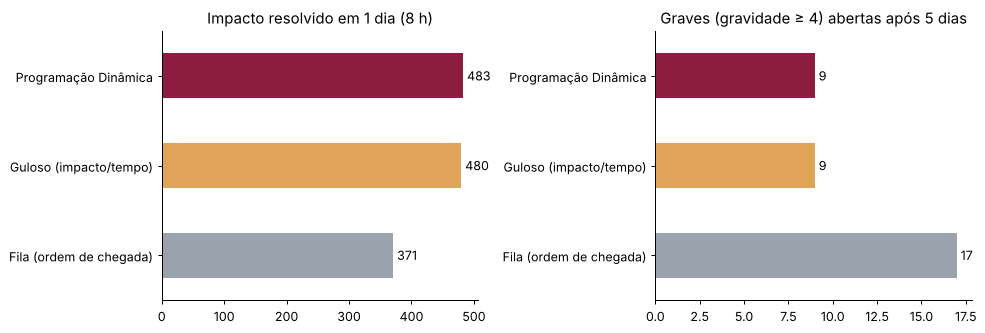

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cores = ["#9aa3ad", "#e0a458", "#8c1d40"]
comparacao["impacto_total"].plot.barh(ax=ax[0], color=cores)
ax[0].set_title("Impacto resolvido em 1 dia (8 h)"); ax[0].set_ylabel("")
comparacao["graves_abertas_fim_semana"].plot.barh(ax=ax[1], color=cores)
ax[1].set_title("Graves (gravidade ≥ 4) abertas após 5 dias"); ax[1].set_ylabel("")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
    for c in a.containers: a.bar_label(c, padding=3)
plt.tight_layout()
plt.savefig("img/comparacao.png", dpi=160)

**Leitura:** em relação à fila por ordem de chegada, o DP resolve **muito mais impacto** com a mesma equipe e deixa **menos ocorrências graves esperando**. Nesta base, o guloso fica perto do DP, mas sem nenhuma garantia: no exemplo da seção 5 ele perdeu 21%. O experimento abaixo mede com que frequência isso acontece.

In [8]:
rng = random.Random(1)
perdas = []
for _ in range(2000):
    inst = [oc(f"X{i}", "-", rng.randint(1, 5), rng.randint(0, 15), rng.randint(0, 30), rng.randint(1, 6))
            for i in range(rng.randint(5, 30))]
    otimo, gul = mochila_dp_valor(inst, JORNADA_BLOCOS), guloso_razao(inst, JORNADA_BLOCOS)[0]
    perdas.append((otimo - gul) / otimo)
perdas = pd.Series(perdas)
print(f"Em 2000 cenários aleatórios, o guloso ficou abaixo do ótimo em {(perdas > 0).mean():.0%} deles.")
print(f"Perda média quando erra: {perdas[perdas > 0].mean():.1%} · Pior caso: {perdas.max():.1%}")

Em 2000 cenários aleatórios, o guloso ficou abaixo do ótimo em 46% deles.
Perda média quando erra: 3.4% · Pior caso: 13.5%


## 8. Eficiência
| Estratégia | Tempo | Memória | Ótimo garantido? |
|---|---|---|---|
| Força bruta (todas as combinações) | O(2ⁿ · n) | O(n) | sim, mas inviável |
| Fila por ordem de chegada | O(n log n) | O(n) | não |
| Guloso por impacto/tempo | O(n log n) | O(n) | não |
| **Programação Dinâmica (tabela)** | **O(n · W)** | **O(n · W)** | **sim** |
| Programação Dinâmica (vetor, só o valor) | O(n · W) | O(W) | sim |

*n* = número de ocorrências, *W* = jornada em blocos (16). Como *W* é pequeno e fixo, o DP é **linear em n** na prática: dobrar as ocorrências dobra o tempo. A complexidade é chamada de **pseudo-polinomial** porque depende do valor de *W*. Por isso o tempo foi discretizado em blocos de 30 minutos, e não em minutos (W = 480 deixaria a tabela 30 vezes maior sem ganho real de precisão).

In [9]:
def cronometrar(f, *args, repeticoes=3):
    melhor = float("inf")
    for _ in range(repeticoes):
        t0 = time.perf_counter(); f(*args); melhor = min(melhor, time.perf_counter() - t0)
    return melhor * 1000  # ms

rng = random.Random(3)
base = [oc(f"B{i}", "-", rng.randint(1, 5), rng.randint(0, 15), rng.randint(0, 30), rng.randint(1, 6))
        for i in range(2000)]
ns_bruta = list(range(4, 19, 2))
t_bruta = [cronometrar(forca_bruta, base[:n], JORNADA_BLOCOS, repeticoes=1) for n in ns_bruta]
t_dp_peq = [cronometrar(mochila_dp, base[:n], JORNADA_BLOCOS) for n in ns_bruta]
ns_dp = [100, 250, 500, 1000, 2000]
t_dp = [cronometrar(mochila_dp, base[:n], JORNADA_BLOCOS) for n in ns_dp]

print("n    força bruta (ms)   DP (ms)")
for n, b, d in zip(ns_bruta, t_bruta, t_dp_peq):
    print(f"{n:<4} {b:>14.2f}   {d:>8.3f}")
print("\nDP com muitas ocorrências (W = 16):")
for n, d in zip(ns_dp, t_dp):
    print(f"  n = {n:>5}: {d:7.1f} ms")

n    força bruta (ms)   DP (ms)
4              0.04      0.009
6              0.07      0.013
8              0.35      0.020
10             0.86      0.020
12             3.25      0.028
14             8.96      0.028
16            32.00      0.031
18           111.75      0.035

DP com muitas ocorrências (W = 16):
  n =   100:     0.2 ms
  n =   250:     0.5 ms
  n =   500:     1.0 ms
  n =  1000:     2.0 ms
  n =  2000:     4.2 ms


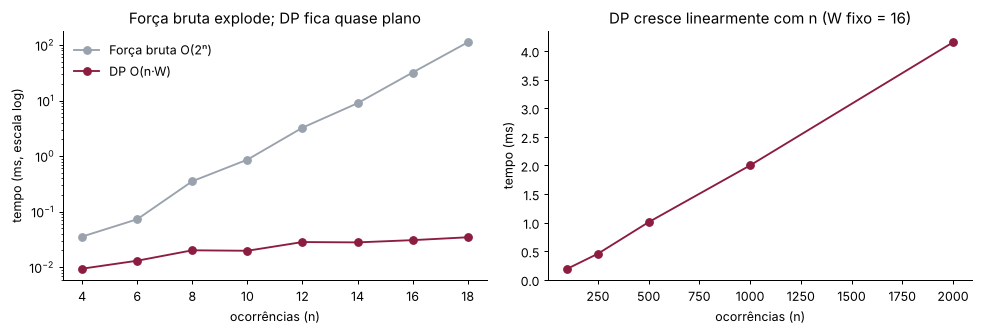

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ns_bruta, t_bruta, "o-", color="#9aa3ad", label="Força bruta O(2ⁿ)")
ax[0].plot(ns_bruta, t_dp_peq, "o-", color="#8c1d40", label="DP O(n·W)")
ax[0].set_yscale("log"); ax[0].set_xlabel("ocorrências (n)"); ax[0].set_ylabel("tempo (ms, escala log)")
ax[0].set_title("Força bruta explode; DP fica quase plano"); ax[0].legend(frameon=False)
ax[1].plot(ns_dp, t_dp, "o-", color="#8c1d40")
ax[1].set_xlabel("ocorrências (n)"); ax[1].set_ylabel("tempo (ms)")
ax[1].set_title("DP cresce linearmente com n (W fixo = 16)")
for a in ax: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("img/eficiencia.png", dpi=160)

## 9. Testes automatizados

In [11]:
r = subprocess.run([sys.executable, "-m", "pytest", "-v", "--no-header", "-p", "no:cacheprovider",
                    "test_priorizacao.py"], capture_output=True, text=True)
print(r.stdout[r.stdout.find("test_priorizacao.py::"):])

test_priorizacao.py::test_impacto_respeita_limites PASSED                [ 12%]
test_priorizacao.py::test_lista_vazia_e_capacidade_zero PASSED           [ 25%]
test_priorizacao.py::test_ocorrencia_maior_que_a_jornada_nao_entra PASSED [ 37%]
test_priorizacao.py::test_contraexemplo_guloso PASSED                    [ 50%]
test_priorizacao.py::test_dp_igual_forca_bruta_em_300_casos_aleatorios PASSED [ 62%]
test_priorizacao.py::test_versao_otimizada_em_memoria_da_o_mesmo_valor PASSED [ 75%]
test_priorizacao.py::test_dp_nunca_perde_para_o_guloso PASSED            [ 87%]
test_priorizacao.py::test_ocorrencia_antiga_ganha_prioridade PASSED      [100%]

============================== 8 passed in 0.09s ===============================



Os testes comparam o DP com a força bruta em 300 cenários aleatórios (mesmo valor ótimo), verificam se a resposta reconstruída cabe na jornada e soma exatamente o valor ótimo, conferem os casos-limite (lista vazia, jornada zero, ocorrência maior que a jornada) e confirmam o contraexemplo do guloso.

## 10. Conclusões
1. **Priorizar ocorrências de zeladoria é um Problema da Mochila 0/1**, e a programação dinâmica encontra a **melhor combinação garantida** em O(n·W). Com W = 16, o algoritmo responde em milissegundos mesmo com milhares de ocorrências.
2. **Contra a fila por ordem de chegada**, o DP resolve muito mais impacto com a mesma equipe e deixa menos problemas graves abertos no fim da semana.
3. **Contra o guloso**, o DP nunca perde. O guloso costuma chegar perto, mas erra em parte dos cenários e pode perder mais de 20% do impacto, como no exemplo da seção 5.
4. **Transparência para o cidadão:** como a pontuação é simples, o Zela Aí pode mostrar ao morador por que a ocorrência dele ficou para amanhã. Os dias em aberto contam pontos, então ela não fica esquecida.

**Limitações e próximos passos:** os tempos e as gravidades são estimativas. Com o Zela Aí em uso, os tempos reais de atendimento substituiriam essas estimativas. O DP é ótimo **para cada dia**, não para a semana inteira; o termo de "dias em aberto" compensa isso na prática. Também seria possível estender o modelo para várias equipes (mochilas múltiplas) e para o deslocamento entre ocorrências (rotas).